# Steam Games Success Prediction: Exploratory Data Analysis (EDA)

This notebook covers the initial exploration and cleaning of the Steam games dataset. The primary goal is to build a model capable of predicting a game's success *before* its release. Therefore, a crucial part of this EDA is identifying and removing any features that could cause data leakage (i.e., information that only becomes available after launch).

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [44]:
df = pd.read_json("../data/raw/games.json", orient="index")
df.index.name = "appid"
df = df.reset_index()
df.shape
df.head()

,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,positive,negative,estimated_owners,average_playtime_forever,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags
0,2539430,Black Dragon Mage Playtest,"Aug 1, 2023",0,0.00,0,,,,,...,0,0,0 - 0,0,0,0,0,0,0,[]
1,496350,Supipara - Chapter 1 Spring Has Come!,"Jul 29, 2016",0,5.24,0,"Springtime, April: when the cherry trees come ...","Springtime, April: when the cherry trees come ...","Spring has come, and our protagonist, Yukinari...",,...,252,3,0 - 20000,8,0,8,0,65,0,"{'Adventure': 27, 'Visual Novel': 19, 'Anime':..."
2,1034400,Mystery Solitaire The Black Raven,"May 6, 2019",0,4.99,0,"Immerse yourself in the most beloved, mystical...","Immerse yourself in the most beloved, mystical...",Discover an entrancing and spectacular world!,,...,21,3,0 - 20000,0,0,0,0,0,0,"{'Casual': 83, 'Card Game': 52, 'Solitaire': 4..."
3,3292190,버튜버 파라노이아 - Vtuber Paranoia,"Oct 31, 2024",0,8.99,1,"synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...","synopsis 'Hello, I'm Hiyoro, a new YouTuber!' ...",Yuha! I'll start the broadcast! Hakko's extrem...,,...,0,0,0 - 20000,0,0,0,0,0,1,[]
4,3631080,Maze Quest VR,"Apr 24, 2025",0,4.99,0,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,Its not just a Maze; its a Quest! Enter the ca...,,...,0,0,0 - 20000,0,0,0,0,0,0,[]


### 1. Removing Irrelevant and Leaky Columns

To ensure the model learns strictly from pre-release data, columns reflecting post-launch performance (Data Leakage) must be dropped. Heavy text columns that are redundant for the baseline model are also removed.

- **Post-release performance metrics (Data Leakage):** `reviews`, `metacritic_score`, `recommendations`, `user_score`, `score_rank`, `positive`, `negative`, `average_playtime_forever`, `average_playtime_2weeks`, `median_playtime_forever`, `median_playtime_2weeks`, `peak_ccu`, `discount` — these metrics are strictly generated by users after the game is released.
- **Dynamic post-release features:** `dlc_count`, `packages`, `notes` — these often change over the game's lifecycle as new DLCs, editions, or bundles are added.
- **Identifiers and external links:** `metacritic_url` — not useful as a direct predictive feature.
- **Redundant long text:** `detailed_description`, `about_the_game` — dropped to simplify the baseline model and avoid NLP bloat. The model will rely on `short_description`, `genres`, `tags` etc.

In [45]:
REMOVE_COLUMNS = [
    "metacritic_url",
    "reviews",
    "metacritic_score",
    "recommendations",
    "user_score",
    "score_rank",
    "positive",
    "negative",
    "average_playtime_forever",
    "average_playtime_2weeks",
    "median_playtime_forever",
    "median_playtime_2weeks",
    "discount",
    "peak_ccu",
    "dlc_count",
    "notes",
    "packages",
    "detailed_description",
    "about_the_game",
]

eda_df = df.drop(columns=REMOVE_COLUMNS).copy()

eda_df.head()
eda_df.columns

Index(['appid', 'name', 'release_date', 'required_age', 'price',
       'short_description', 'header_image', 'website', 'support_url',
       'support_email', 'windows', 'mac', 'linux', 'achievements',
       'supported_languages', 'full_audio_languages', 'developers',
       'publishers', 'categories', 'genres', 'screenshots', 'movies',
       'estimated_owners', 'tags'],
      dtype='str')

In [46]:
eda_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 147352 entries, 0 to 147351
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   appid                 147352 non-null  int64  
 1   name                  147352 non-null  str    
 2   release_date          147352 non-null  str    
 3   required_age          147352 non-null  int64  
 4   price                 147352 non-null  float64
 5   short_description     147352 non-null  str    
 6   header_image          147352 non-null  str    
 7   website               147352 non-null  str    
 8   support_url           147352 non-null  str    
 9   support_email         147352 non-null  str    
 10  windows               147352 non-null  bool   
 11  mac                   147352 non-null  bool   
 12  linux                 147352 non-null  bool   
 13  achievements          147352 non-null  int64  
 14  supported_languages   147352 non-null  object 
 15  full_audio_

### 2. Missing Values Inspection

Checked the dataset for missing values, including:
- Actual NaN values.
- Empty strings.
- String representations of missing values (e.g. "None", "NaN", "N/A").
- Empty lists and dicts

In [47]:
empty_values = eda_df.select_dtypes(include=["str", "object"]).apply(
    lambda col: col.astype(str).str.strip().isin(["", "[]", "{}"]).sum()
)

missing_strings = eda_df.select_dtypes(include=["str", "object"]).apply(
    lambda col: (
        col.astype(str)
        .str.lower()
        .str.strip()
        .isin(["nan", "none", "null", "n/a"])
        .sum()
    )
)

real_nans = eda_df.select_dtypes(include=["str", "object"]).isna().sum()

pd.DataFrame(
    {
        "empty_strings_or_lists": empty_values,
        "text_missing_flags": missing_strings,
        "real_nans": real_nans,
    }
).sort_values("empty_strings_or_lists", ascending=False)

,empty_strings_or_lists,text_missing_flags,real_nans
movies,147352,0,0
website,90858,0,0
full_audio_languages,88154,0,0
support_url,84363,93,0
tags,63963,0,0
support_email,24936,29,0
categories,8980,0,0
publishers,8856,0,0
developers,8456,0,0
genres,8437,0,0


All movies are empty so I removed them

In [48]:
eda_df = eda_df.drop(columns="movies").copy()

### 3. Duplicate Records Inspection

Checked the dataset for duplicate Steam application IDs and game names to identify potential duplicate records.

In [49]:
print(eda_df.appid.duplicated().sum(), eda_df.name.duplicated().sum())

duplicates = eda_df[eda_df["name"].duplicated(keep=False)]

duplicates[["appid", "name", "estimated_owners"]].sort_values("name").head(20)

0 1520


,appid,name,estimated_owners
63915,942050,2048,20000 - 50000
124949,4358080,2048,0 - 0
30085,3022780,A Better Tomorrow,0 - 20000
108086,3763930,A Better Tomorrow,0 - 0
53193,557900,A Walk in the Woods,0 - 20000
62608,842420,A Walk in the Woods,100000 - 200000
17238,1544540,ALONE,50000 - 100000
100222,1826070,ALONE,0 - 20000
23341,1768480,ASTRA,0 - 20000
87683,2691830,ASTRA,20000 - 50000


**Findings:**
- No duplicate Steam application IDs were found.
- 1,520 duplicate game names were identified.
- Duplicate names represent different Steam applications and are not necessarily duplicate records.

No records were removed.

### 4. Target variable inspection

In [50]:
eda_df.estimated_owners.value_counts(dropna=False).sort_index()

estimated_owners
0 - 0                    44142
0 - 20000                77624
100000 - 200000           3458
1000000 - 2000000          729
10000000 - 20000000         51
100000000 - 200000000        4
20000 - 50000            11402
200000 - 500000           2857
2000000 - 5000000          405
20000000 - 50000000         31
50000 - 100000            5360
500000 - 1000000          1155
5000000 - 10000000         125
50000000 - 100000000         9
Name: count, dtype: int64

### Remove records with unknown owner estimates

Removed records where `estimated_owners == "0 - 0"`.
These records do not provide a meaningful owner estimate and may include
applications without sufficient SteamSpy data.

In [51]:
eda_df = eda_df[eda_df["estimated_owners"] != "0 - 0"].copy()

print(len(eda_df))
print(eda_df["estimated_owners"].value_counts())

103210
estimated_owners
0 - 20000                77624
20000 - 50000            11402
50000 - 100000            5360
100000 - 200000           3458
200000 - 500000           2857
500000 - 1000000          1155
1000000 - 2000000          729
2000000 - 5000000          405
5000000 - 10000000         125
10000000 - 20000000         51
20000000 - 50000000         31
50000000 - 100000000         9
100000000 - 200000000        4
Name: count, dtype: int64


In [52]:
eda_df.estimated_owners.describe()

count        103210
unique           13
top       0 - 20000
freq          77624
Name: estimated_owners, dtype: object

**Visualizing the Distribution**

Visualizing the distribution of estimated owners to assess the balance of our future target variable.

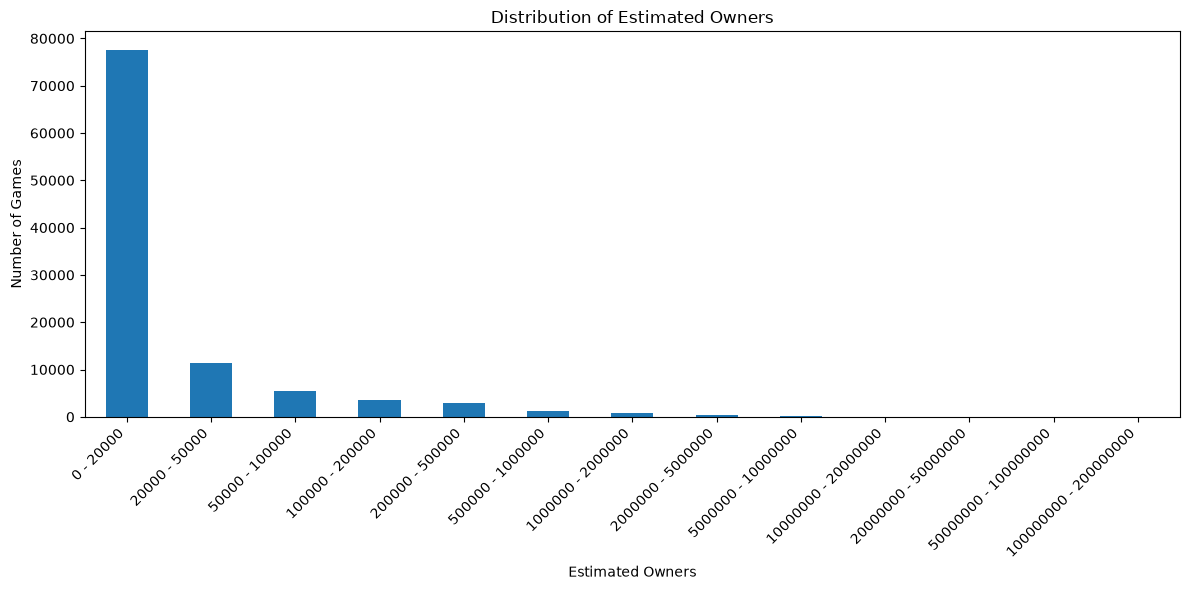

In [53]:
owner_counts = eda_df["estimated_owners"].value_counts()

plt.figure(figsize=(12, 6))
owner_counts.plot(kind="bar")
plt.title("Distribution of Estimated Owners")
plt.xlabel("Estimated Owners")
plt.ylabel("Number of Games")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 5. Target Engineering (Age-Adjusted) & Data Leakage Prevention

Since our goal is to predict a game's potential **before release**, we cannot directly compare sales metrics of games released 10 years ago with games released recently. 

Key steps in this transformation:
1. **Time-Aware Scaling:** Computed a temporary `age_in_months` feature to track the game's lifetime on the market.
2. **Market Saturation (`market_competition`):** Created a feature mapping the total volume of releases in a game's launch year to account for market density.
3. **Age-Adjusted Target Variable (`success_tier` / `target_num`):** Applied dynamic thresholds to classify success, setting lower owner requirements for games under 12 months old. This ensures target categories reflect true popularity rather than accumulated long-term sales.
4. **Data Leakage Cleanup:** Dropped exact release dates and `age_in_months`, as these will be unknown (or zero) for pre-release predictions. Retained `release_month` to capture seasonality.

In [54]:
eda_df["release_date"] = pd.to_datetime(eda_df["release_date"], errors="coerce")

CURRENT_DATE = eda_df["release_date"].max()

eda_df["age_in_months"] = (
    CURRENT_DATE.to_period("M") - eda_df["release_date"].dt.to_period("M")
).apply(lambda x: x.n if pd.notnull(x) else np.nan)
eda_df["age_in_months"] = eda_df["age_in_months"].fillna(1).replace(0, 1).astype(int)

eda_df["release_month"] = eda_df["release_date"].dt.month.fillna(0).astype(int)

games_per_year = eda_df["release_date"].dt.year.value_counts().to_dict()
eda_df["market_competition"] = (
    eda_df["release_date"].dt.year.map(games_per_year).fillna(15000).astype(int)
)


def get_tier_with_age(row):
    owners_str = row["estimated_owners"]
    age = row["age_in_months"]

    low_sales = ["0 - 20000"]
    medium_sales_young = ["20000 - 50000"]
    medium_sales_old = ["20000 - 50000", "50000 - 100000", "100000 - 200000"]

    if age <= 12:
        if owners_str in low_sales:
            return "Low"
        elif owners_str in medium_sales_young:
            return "Medium"
        else:
            return "High"

    else:
        if owners_str in low_sales:
            return "Low"
        elif owners_str in medium_sales_old:
            return "Medium"
        else:
            return "High"


eda_df["success_tier"] = eda_df.apply(get_tier_with_age, axis=1)
tier_mapping = {"Low": 0, "Medium": 1, "High": 2}
eda_df["target_num"] = eda_df["success_tier"].map(tier_mapping)

eda_df = eda_df.drop(columns=["release_date", "age_in_months", "estimated_owners"])

print(
    eda_df[["release_month", "market_competition", "success_tier", "target_num"]].head()
)

   release_month  market_competition success_tier  target_num
1              7                4128          Low           0
2              5                7229          Low           0
3             10               15555          Low           0
4              4               14680          Low           0
5              4               11675          Low           0


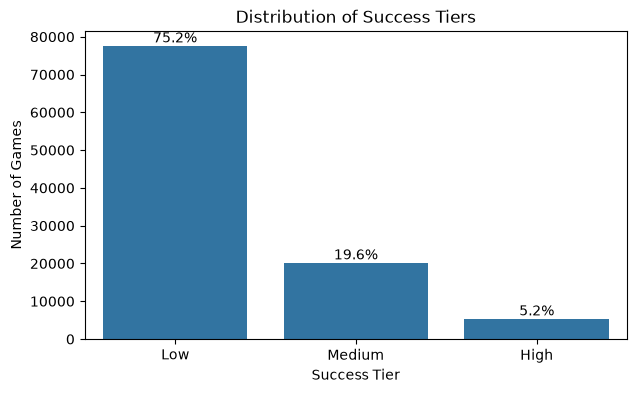

In [55]:
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=eda_df, x="success_tier", order=["Low", "Medium", "High"])

total_games = len(eda_df)

for container in ax.containers:
    ax.bar_label(container, fmt=lambda x: f"{(x / total_games) * 100:.1f}%")

plt.title("Distribution of Success Tiers")
plt.xlabel("Success Tier")
plt.ylabel("Number of Games")
plt.show()

Dropped the categorical `success_tier` string column. The machine learning model will strictly rely on the numerically encoded `target_num`.

In [56]:
eda_df = eda_df.drop(columns=["success_tier"])

### 6. Numerical variables


**Screenshot Count:**

The `screenshots` column contains lists of image URLs. This is transformed into a numerical feature representing the total number of screenshots provided for the game.

In [57]:
eda_df["screenshots_count"] = eda_df["screenshots"].apply(
    lambda x: len(x) if isinstance(x, list) else 0
)
eda_df = eda_df.drop(columns=["screenshots"])

print(eda_df["screenshots_count"].describe())

count    103210.000000
mean          9.010590
std           5.568435
min           0.000000
25%           5.000000
50%           7.000000
75%          10.000000
max         183.000000
Name: screenshots_count, dtype: float64


In [58]:
numeric_columns = eda_df.select_dtypes(include="number").columns

eda_df[numeric_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
appid,103210.0,1.807927e+06,1.044579e+06,10.0,933292.50,1671500.00,2618152.50,5412860.00
required_age,103210.0,2.009398e-01,1.809547e+00,0.0,0.00,0.00,0.00,21.00
price,103210.0,5.424841e+00,1.181943e+01,0.0,0.99,2.99,6.49,999.98
achievements,103210.0,2.059726e+01,1.538181e+02,0.0,0.00,6.00,21.00,9821.00
release_month,103210.0,6.672570e+00,3.406836e+00,1.0,4.00,7.00,10.00,12.00
market_competition,103210.0,1.005650e+04,4.130952e+03,1.0,7434.00,10100.00,14680.00,15555.00
target_num,103210.0,3.000194e-01,5.605755e-01,0.0,0.00,0.00,0.00,2.00
screenshots_count,103210.0,9.010590e+00,5.568435e+00,0.0,5.00,7.00,10.00,183.00


### 7. Categorical Variables Exploration

Several metadata columns and operating system indicators are semantically binary (Yes/No or True/False). These are converted into integer flags (1 or 0) so they can be processed by machine learning algorithms.

**Creating Boolean Flags:**
- Converted presence of URLs and images (`header_image`, `website`, `support_url`, `support_email`) into binary `has_...` indicators.
- Converted platform support (`windows`, `mac`, `linux`) from booleans to integers.

In [59]:
columns_to_flag = ["header_image", "website", "support_url", "support_email"]

for col in columns_to_flag:
    eda_df[f"has_{col}"] = (
        eda_df[col].fillna("").astype(str).str.strip() != ""
    ).astype(int)

eda_df = eda_df.drop(columns=columns_to_flag)

platform_columns = ["windows", "mac", "linux"]
for col in platform_columns:
    eda_df[col] = eda_df[col].astype(int)

flag_cols = [f"has_{c}" for c in columns_to_flag] + platform_columns
print(eda_df[flag_cols].head())

   has_header_image  has_website  has_support_url  has_support_email  windows  \
1                 1            1                1                  1        1   
2                 1            1                1                  1        1   
3                 1            0                0                  1        1   
4                 1            1                1                  1        1   
5                 1            0                1                  1        1   

   mac  linux  
1    0      0  
2    1      0  
3    0      0  
4    0      0  
5    0      0  


**Exploring List-Based Features:**

Columns like `genres`, `categories`, `tags`, `developers`, and `publishers` contain lists of strings. To assess market composition and prepare for future encoding, these lists are flattened to extract and review the most frequent values.

In [60]:
from collections import Counter

genre_counts = Counter(genre for genres in eda_df["genres"] for genre in genres)

pd.Series(genre_counts).sort_values(ascending=False).head(20)

Indie                    73250
Casual                   44564
Action                   42112
Adventure                41296
Simulation               21998
Strategy                 20270
RPG                      19094
Early Access             10096
Free To Play              5898
Sports                    4372
Racing                    3648
Massively Multiplayer     1946
Utilities                  909
Design & Illustration      531
Animation & Modeling       412
Violent                    410
Education                  403
Video Production           291
Game Development           269
Gore                       255
dtype: int64

In [61]:
category_counts = Counter(
    category for categories in eda_df["categories"] for category in categories
)

pd.Series(category_counts).sort_values(ascending=False).head(20)

Single-player                   98192
Family Sharing                  92690
Steam Achievements              52298
Steam Cloud                     29280
Full controller support         24021
Multi-player                    18099
Partial Controller Support      12846
Steam Trading Cards             11290
PvP                             10954
Co-op                            9994
Steam Leaderboards               8662
Online PvP                       7615
Remote Play Together             7305
Shared/Split Screen              6940
Online Co-op                     6016
Custom Volume Controls           5572
Tracked Controller Support       5417
VR Only                          5320
Playable without Timed Input     5246
Shared/Split Screen PvP          4771
dtype: int64

In [62]:
eda_df["tags"] = eda_df["tags"].apply(
    lambda x: list(x.keys()) if isinstance(x, dict) else []
)

tag_counts = Counter(tag for tags in eda_df["tags"] for tag in tags)

pd.Series(tag_counts).sort_values(ascending=False).head(20)

Singleplayer      50375
Indie             48574
Action            36830
Casual            36575
Adventure         35215
2D                26801
3D                18005
Simulation        17902
Strategy          17863
Puzzle            16376
Atmospheric       16290
RPG               15755
Colorful          14266
Pixel Graphics    13875
Story Rich        13350
Exploration       13245
Cute              12683
First-Person      12302
Fantasy           11510
Arcade            11499
dtype: int64

**Language Features Text Cleaning:**

Parsing issues in the Steam API led to HTML noise and formatting characters inside `supported_languages` and `full_audio_languages`.


In [63]:
eda_df["full_audio_languages"].explode().value_counts().tail(10)

full_audio_languages
Japanese &amp;amp;amp;amp;lt;br /&amp;amp;amp;amp;gt;&amp;amp;amp;amp;lt;br /&amp;amp;amp;amp;gt;&amp;amp;amp;amp;lt;strong&amp;amp;amp;amp;gt;&amp;amp;amp;amp;lt;/strong&amp;amp;amp;amp;gt;     3
German[b][/b]                                                                                                                                                                                      2
Italian \r\n\r\n[b][/b]                                                                                                                                                                            1
Russian\r\n[b][/b]                                                                                                                                                                                 1
French[b][/b]                                                                                                                                                                                  

In [64]:
eda_df["supported_languages"].explode().value_counts().tail(10)

supported_languages
Traditional Chinese (text only)    1
Hungarian,Polish                   1
Russian\r\n[b][/b]                 1
English Dutch  English             1
French[b][/b]                      1
Italian[b][/b]                     1
Spanish - Spain[b][/b]             1
Korean[b][/b]                      1
Japanese \r\n\r\n[b][/b]           1
Spanish - Spain\r\n[b][/b]         1
Name: count, dtype: int64

In [65]:
import re


def clean_languages_list(raw_value):
    if isinstance(raw_value, list):
        text = ", ".join(map(str, raw_value))
    elif isinstance(raw_value, str):
        text = raw_value
    else:
        return []

    text = (
        text.replace("&amp;", "")
        .replace("amp;", "")
        .replace("lt;", "<")
        .replace("gt;", ">")
    )

    text = re.sub(r"<.*?>", "", text)
    text = re.sub(r"\[.*?\]", "", text)

    text = text.replace("\r", ",").replace("\n", ",")

    cleaned_list = [lang.strip() for lang in text.split(",") if lang.strip()]

    final_list = []
    for lang in cleaned_list:
        if "all with full audio support" in lang:
            final_list.append("Japanese")
        elif lang.startswith("category_"):
            continue
        else:
            final_list.append(lang)

    return list(set(final_list))


eda_df["supported_languages"] = eda_df["supported_languages"].apply(
    clean_languages_list
)
eda_df["full_audio_languages"] = eda_df["full_audio_languages"].apply(
    clean_languages_list
)

In [66]:
eda_df["supported_languages"].explode().value_counts().tail(10)

supported_languages
Dari                               683
K'iche'                            682
Tigrinya                           682
Wolof                              682
Cherokee                           682
English (full audio)                 3
#lang_slovakian                      2
German;                              2
Traditional Chinese (text only)      1
English Dutch  English               1
Name: count, dtype: int64

In [67]:
eda_df["full_audio_languages"].explode().value_counts().tail(10)

full_audio_languages
Sotho       489
Wolof       489
Quechua     489
Konkani     488
K'iche'     488
Sorani      488
Tigrinya    488
Cherokee    488
Dari        488
Assamese    488
Name: count, dtype: int64

In [68]:
dev_counts = Counter(dev for devs in eda_df["developers"] for dev in devs)
print("Top 10 Developers:")
print(pd.Series(dev_counts).sort_values(ascending=False).head(10))

pub_counts = Counter(pub for pubs in eda_df["publishers"] for pub in pubs)
print("\nTop 10 Publishers:")
print(pd.Series(pub_counts).sort_values(ascending=False).head(10))

Top 10 Developers:
EroticGamesClub               230
Choice of Games               175
Boogygames Studios            149
Creobit                       145
Laush Dmitriy Sergeevich      133
Bully Revenge Studios         127
Tero Lunkka                   127
Gamesforgames                 123
KOEI TECMO GAMES CO., LTD.    122
Cyber Keks                    119
dtype: int64

Top 10 Publishers:
BFG Entertainment    531
8floor               268
EroticGamesClub      230
Conglomerate 5       197
Strategy First       194
Kagura Games         192
PlayWay S.A.         188
HH-Games             184
Choice of Games      175
THQ Nordic           171
dtype: int64


### 8. Feature Importance Analysis

**Correlation Matrix for Numerical and Binary Features:**

Evaluating linear relationships between numerical/binary features and the target variable (`target_num`). A heatmap and a horizontal bar chart are used to visualize the strength and direction of these correlations.

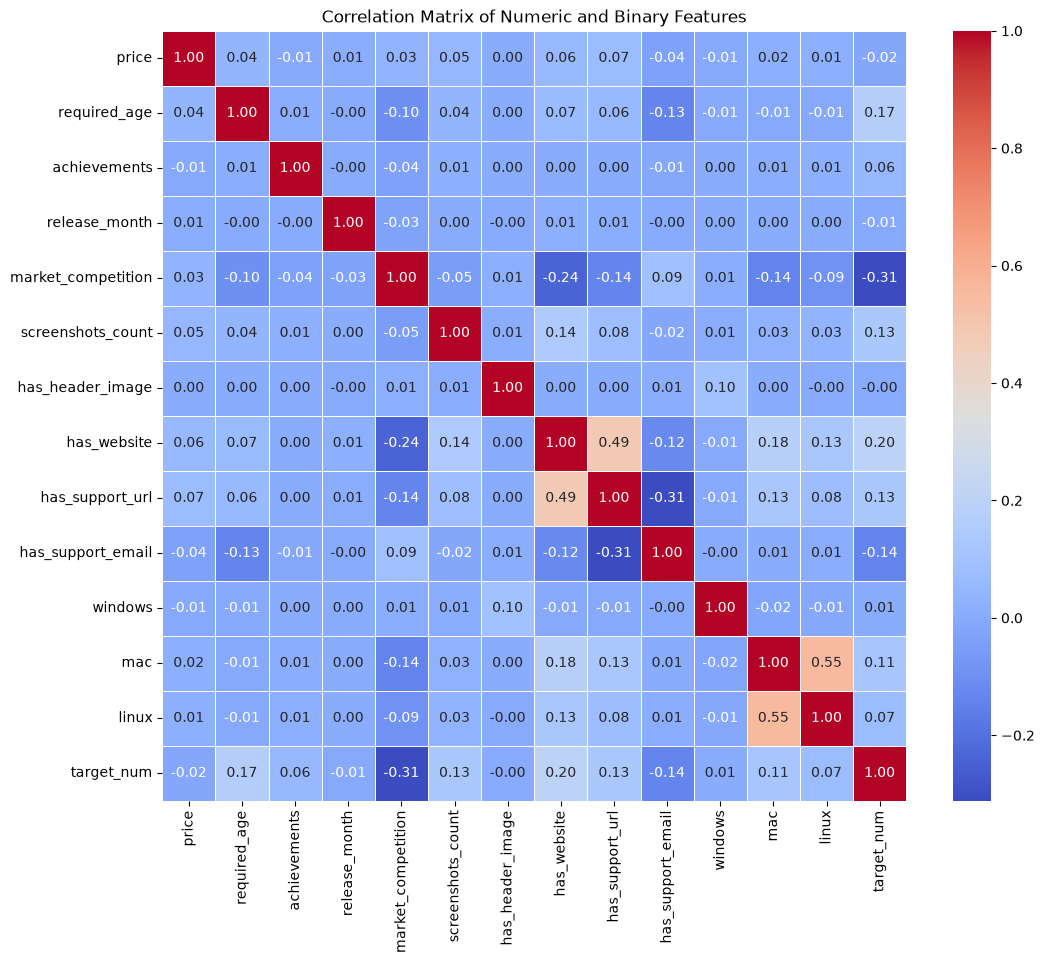

In [69]:
num_cols = [
    "price",
    "required_age",
    "achievements",
    "release_month",
    "market_competition",
    "screenshots_count",
    "has_header_image",
    "has_website",
    "has_support_url",
    "has_support_email",
    "windows",
    "mac",
    "linux",
    "target_num",
]

plt.figure(figsize=(12, 10))
sns.heatmap(
    eda_df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title("Correlation Matrix of Numeric and Binary Features")
plt.show()

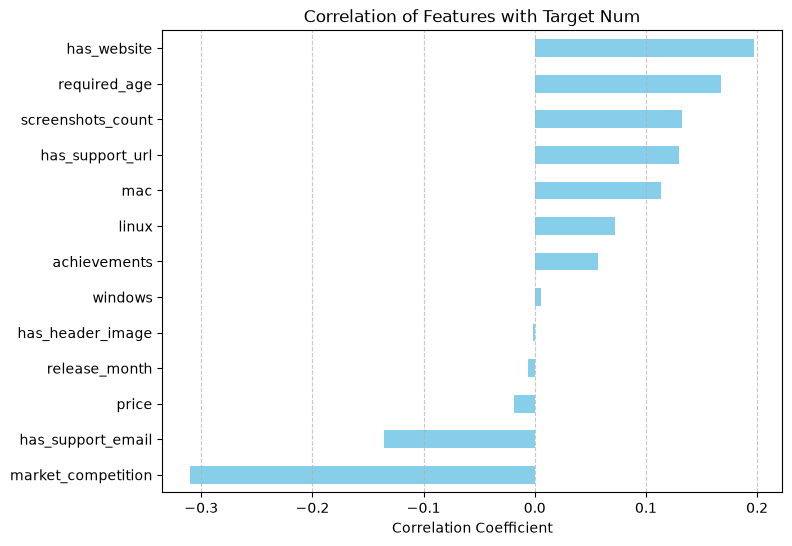

In [70]:
plt.figure(figsize=(8, 6))
eda_df[num_cols].corr()["target_num"].drop("target_num").sort_values().plot(
    kind="barh", color="skyblue"
)
plt.title("Correlation of Features with Target Num")
plt.xlabel("Correlation Coefficient")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.show()

**Mutual Information for Categorical Features:**

Assessing the non-linear relationship between binary categorical features and the target variable using Mutual Information scores. Higher scores indicate a stronger dependency.

In [71]:
from sklearn.metrics import mutual_info_score


def calculate_mi(series):
    return mutual_info_score(series, eda_df["target_num"])


binary_cat_cols = [
    "has_header_image",
    "has_website",
    "has_support_url",
    "has_support_email",
    "windows",
    "mac",
    "linux",
]

df_mi = eda_df[binary_cat_cols].apply(calculate_mi)
df_mi = df_mi.sort_values(ascending=False).to_frame(name="MI_score")

print("Mutual Information Scores:")
print(df_mi)

Mutual Information Scores:
                   MI_score
has_website        0.019887
has_support_email  0.008752
has_support_url    0.008725
mac                0.005955
linux              0.002460
windows            0.000025
has_header_image   0.000010


**Word Cloud for Text Analysis:**

Providing a visual baseline of the most frequent terms used in the `short_description` column. This helps identify common vocabulary and informs future Natural Language Processing (NLP) feature engineering.

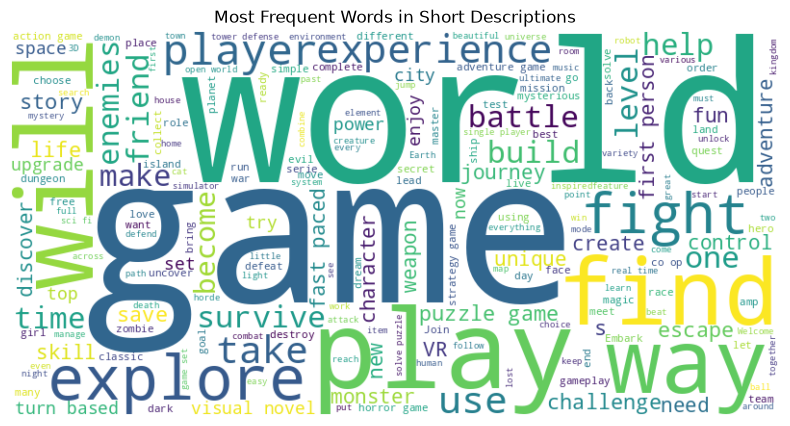

In [72]:
from wordcloud import WordCloud

text = " ".join(desc for desc in eda_df["short_description"].dropna())

wordcloud = WordCloud(width=800, height=400, background_color="white").generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Most Frequent Words in Short Descriptions")
plt.show()

**Adjusted Mutual Information and Impact Analysis for Multi-Label Features:**

Analyzing complex list-based categorical features (`genres`, `categories`, `tags`, and `languages`) using Adjusted Mutual Information (AMI) and mean target variance. 

`MultiLabelBinarizer` is used to temporarily one-hot encode these lists. The directional impact (Positive/Negative) of each individual label is evaluated by comparing the label's mean success rate against the global dataset mean.

In [73]:
global_mean = eda_df["target_num"].mean()
print(f"Global mean success: {global_mean:.3f}\n")

Global mean success: 0.300



In [74]:
from sklearn.metrics import adjusted_mutual_info_score
from sklearn.preprocessing import MultiLabelBinarizer


def analyze_multilabel_feature(df, column_name, prefix):
    mlb = MultiLabelBinarizer()

    encoded_data = pd.DataFrame(
        mlb.fit_transform(df[column_name].fillna("")),
        columns=[f"{prefix}_{item}" for item in mlb.classes_],
        index=df.index,
    )

    analysis_results = []

    for col in encoded_data.columns:
        ami = adjusted_mutual_info_score(encoded_data[col], df["target_num"])
        feature_mean = df.loc[encoded_data[col] == 1, "target_num"].mean()

        diff = feature_mean - global_mean
        impact = "Positive" if diff > 0 else "Negative"

        clean_name = col.replace(f"{prefix}_", "")

        analysis_results.append(
            {
                "Feature": clean_name,
                "AMI_Score": ami,
                "Mean_Success": feature_mean,
                "Difference": diff,
                "Impact": impact,
            }
        )

    result_df = pd.DataFrame(analysis_results).sort_values(
        by="AMI_Score", ascending=False
    )
    return result_df

In [75]:
# 1. Genres
genre_ami_df = analyze_multilabel_feature(eda_df, "genres", "genre")
print("Top 10 Genres by Adjusted Mutual Information:")
print(genre_ami_df.head(10).to_string(index=False))
print("\n" + "=" * 50 + "\n")

# 2. Categories
category_ami_df = analyze_multilabel_feature(eda_df, "categories", "category")
print("Top 10 Categories by Adjusted Mutual Information:")
print(category_ami_df.head(10).to_string(index=False))
print("\n" + "=" * 50 + "\n")

# 3. Tags
tag_ami_df = analyze_multilabel_feature(eda_df, "tags", "tag")
print("Top 10 Tags by Adjusted Mutual Information:")
print(tag_ami_df.head(10).to_string(index=False))
print("\n" + "=" * 50 + "\n")

# 4. Full audio languages
full_audio_language_ami_df = analyze_multilabel_feature(
    eda_df, "full_audio_languages", "full_audio_language"
)
print("Top 10 Full Audio Languages by Adjusted Mutual Information:")
print(full_audio_language_ami_df.head(10).to_string(index=False))
print("\n" + "=" * 50 + "\n")

# 5. Supported languages
supported_language_ami_df = analyze_multilabel_feature(
    eda_df, "supported_languages", "supported_language"
)
print("Top 10 Supported Languages by Adjusted Mutual Information:")
print(supported_language_ami_df.head(10).to_string(index=False))
print("\n" + "=" * 50 + "\n")

Top 10 Genres by Adjusted Mutual Information:
              Feature  AMI_Score  Mean_Success  Difference   Impact
               Casual   0.013912      0.213446   -0.086574 Negative
         Free To Play   0.012670      0.563411    0.263392 Positive
Massively Multiplayer   0.006058      0.607400    0.307380 Positive
                  RPG   0.004725      0.388080    0.088061 Positive
                Indie   0.004574      0.276710   -0.023309 Negative
         Early Access   0.003148      0.208399   -0.091620 Negative
             Strategy   0.002343      0.361026    0.061007 Positive
               Action   0.002291      0.333658    0.033638 Positive
            Adventure   0.001039      0.318772    0.018752 Positive
           Simulation   0.000518      0.290936   -0.009084 Negative


Top 10 Categories by Adjusted Mutual Information:
              Feature  AMI_Score  Mean_Success  Difference   Impact
  Steam Trading Cards   0.110745      0.911249    0.611230 Positive
Remote Play on Tab

### 9. Exporting Processed Data

Saving the cleaned, engineered, and structured dataset to a JSON file. This processed file serves as the input artifact for the upcoming machine learning modeling phase.

In [76]:
eda_df.to_json(
    "../data/processed/steam_games_processed.json", orient="records", indent=4
)